# Sesiunea 7 - Regresie Logistică pe Iris

Notebook-ul acesta este un laborator pe `LogisticRegression` folosind datasetul **Iris** din `sklearn`.

Nu implementăm algoritmul de la zero. Folosim `sklearn`, ca într-un proiect real, și ne concentrăm pe întrebările care contează:

- cum arată un baseline "fără model";
- ce face `predict_proba()` și cum diferă de `predict()`;
- ce înseamnă praguri de decizie;
- ce metrici alegem pentru cazul nostru;
- cum forțăm modelul să underfit-uiască;
- cum îl facem să overfit-uiască;
- cum găsim o zonă bună între cele două;
- ce cod merită scris de noi și ce lăsăm bibliotecii;
- ce teme mai avansate putem explora la final.

Iris are 3 clase de flori:

- `setosa`
- `versicolor`
- `virginica`

Este mic, curat și foarte bun pentru învățare, dar are și o mică dificultate reală: `versicolor` și `virginica` se suprapun parțial.


## Setup

Dacă rulezi într-un mediu gol, instalează pachetele o singură dată. Apoi rulează notebook-ul de sus până jos.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Stack-ul de bază: calcule numerice, tabele și grafice.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset mic, curat, inclus direct în sklearn.
from sklearn.datasets import load_iris

# Baseline fără învățare reală: util ca punct de comparație.
from sklearn.dummy import DummyClassifier

# Interpretare: cât scade scorul dacă stricăm câte un feature.
from sklearn.inspection import permutation_importance

# Modelul principal al lecției.
from sklearn.linear_model import LogisticRegression

# Metrici și vizualizări pentru clasificare.
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Split, cross-validation și căutare de hiperparametri.
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

# Pipeline = pașii de preprocessing + modelul, legați într-un flux reproductibil.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, label_binarize

# O singură sursă de randomness, ca rezultatele să fie reproductibile.
RANDOM_STATE = 42

# Stil comun pentru graficele din notebook.
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


## 1. Datele

Iris are 150 de exemple, 4 variabile numerice și 3 clase. Variabilele sunt măsurători ale sepalelor și petalelor.

Pentru logistic regression, asta este comod: nu avem valori lipsă, nu avem text de procesat și putem vedea repede ce învață modelul.


In [2]:
# Încărcăm Iris direct ca DataFrame, ca să păstrăm numele coloanelor.
iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target.copy()
class_names = list(iris.target_names)

# Construim un DataFrame complet doar pentru explorare și afișări prietenoase.
# Modelul va primi separat X și y, ca într-un workflow standard de ML.
df = X.copy()
df["species_id"] = y
df["species"] = y.map(dict(enumerate(class_names)))

# Primele verificări: cum arată datele, câte rânduri avem și dacă targetul e echilibrat.
display(df.head())
print("Clase:", class_names)
print("Dimensiune:", df.shape)
display(df["species"].value_counts())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Clase: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Dimensiune: (150, 6)


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [3]:
# Media și deviația standard pe fiecare specie ne arată rapid ce feature-uri separă clasele.
display(df.groupby("species")[X.columns].agg(["mean", "std"]).round(2))


sepal length (cm)       sepal width (cm)       petal length (cm)  \
                        mean   std             mean   std              mean   
species                                                                       
setosa                  5.01  0.35             3.43  0.38              1.46   
versicolor              5.94  0.52             2.77  0.31              4.26   
virginica               6.59  0.64             2.97  0.32              5.55   

                 petal width (cm)        
             std             mean   std  
species                                  
setosa      0.17             0.25  0.11  
versicolor  0.47             1.33  0.20  
virginica   0.55             2.03  0.27

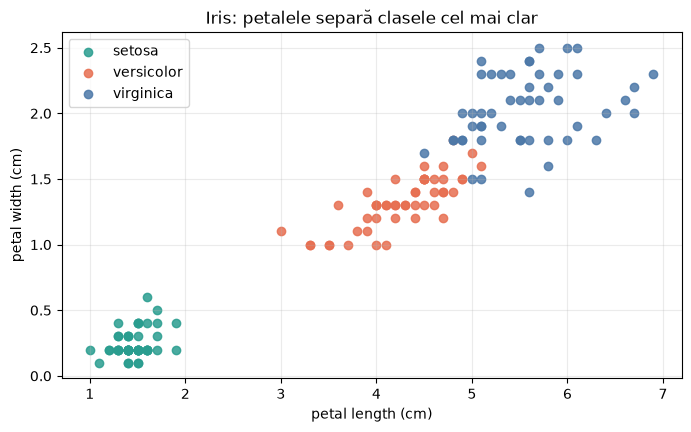

In [4]:
# Vizualizăm cele mai intuitive două feature-uri: lungimea și lățimea petalei.
# Dacă separarea se vede deja în grafic, un model liniar are șanse bune să meargă bine.
colors = {"setosa": "#2a9d8f", "versicolor": "#e76f51", "virginica": "#4c78a8"}

for species, group in df.groupby("species"):
    plt.scatter(
        group["petal length (cm)"],
        group["petal width (cm)"],
        label=species,
        alpha=0.85,
        color=colors[species],
    )

plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.title("Iris: petalele separă clasele cel mai clar")
plt.legend()
plt.show()


## 2. Train/test split

Folosim `stratify=y`, ca fiecare clasă să rămână reprezentată proporțional în train și test.

La Iris, datasetul este mic. Asta înseamnă că scorurile pot varia destul de mult dacă schimbi `random_state`. Într-un proiect real am folosi cross-validation pentru concluzii mai stabile.


In [5]:
# Separăm datele înainte de orice evaluare, ca testul să simuleze date nevăzute.
# stratify=y păstrează aceeași proporție a celor 3 specii în train și test.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Verificăm dimensiunile și distribuția claselor; dacă distribuțiile diferă mult, evaluarea devine fragilă.
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Distribuție train:")
display(y_train.map(dict(enumerate(class_names))).value_counts())
print("Distribuție test:")
display(y_test.map(dict(enumerate(class_names))).value_counts())


Train: (105, 4) Test: (45, 4)
Distribuție train:


target
versicolor    35
setosa        35
virginica     35
Name: count, dtype: int64

Distribuție test:


target
virginica     15
versicolor    15
setosa        15
Name: count, dtype: int64

## 3. Baseline: cum arată "fără nimic"?

Primul model nu trebuie să fie logistic regression. Primul model trebuie să fie un baseline.

`DummyClassifier(strategy="most_frequent")` prezice mereu clasa majoritară. În Iris clasele sunt echilibrate, deci baseline-ul va fi slab.


In [6]:
# Baseline: prezice mereu clasa cea mai frecventă din train.
# Nu este un model bun, ci o limită minimă pe care modelul real trebuie să o bată clar.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

# Păstrăm atât etichetele, cât și probabilitățile, pentru comparațiile de mai jos.
dummy_pred = dummy.predict(X_test)
dummy_proba = dummy.predict_proba(X_test)

print(classification_report(y_test, dummy_pred, target_names=class_names, zero_division=0))
print("Accuracy:", round(accuracy_score(y_test, dummy_pred), 3))


              precision    recall  f1-score   support

      setosa       0.33      1.00      0.50        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.00      0.00      0.00        15

    accuracy                           0.33        45
   macro avg       0.11      0.33      0.17        45
weighted avg       0.11      0.33      0.17        45

Accuracy: 0.333


Un baseline slab este util: ne spune de unde plecăm. Dacă un model mai complicat nu bate clar baseline-ul, problema nu este "să mai tunăm puțin", ci să ne întrebăm dacă datele, targetul sau evaluarea sunt greșite.


## 4. Logistic Regression simplu

Pornim cu o regresie logistică multinomială standard:

- `StandardScaler`, pentru că modelul lucrează cu coeficienți;
- `LogisticRegression`, fără cod scris de la zero;
- `Pipeline`, ca transformările să fie aplicate corect.


In [7]:
# Pipeline-ul previne greșeli clasice: scalerul se învață pe train și se aplică apoi pe test.
# StandardScaler contează pentru regresia logistică, fiindcă modelul compară coeficienți pe scări diferite.
logistic = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)

# Fit = modelul învață coeficienții din train.
logistic.fit(X_train, y_train)

# predict = eticheta finală; predict_proba = probabilitățile pe clase.
y_pred = logistic.predict(X_test)
y_proba = logistic.predict_proba(X_test)

# Pentru multiclass echilibrat, accuracy și macro F1 sunt ambele utile.
# Log loss verifică și calitatea probabilităților, nu doar eticheta câștigătoare.
print(classification_report(y_test, y_pred, target_names=class_names))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 3))
print("Log loss:", round(log_loss(y_test, y_proba), 3))
print("AUC ROC OvR:", round(roc_auc_score(y_test, y_proba, multi_class="ovr"), 3))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

Accuracy: 0.911
Macro F1: 0.911
Log loss: 0.21
AUC ROC OvR: 0.996


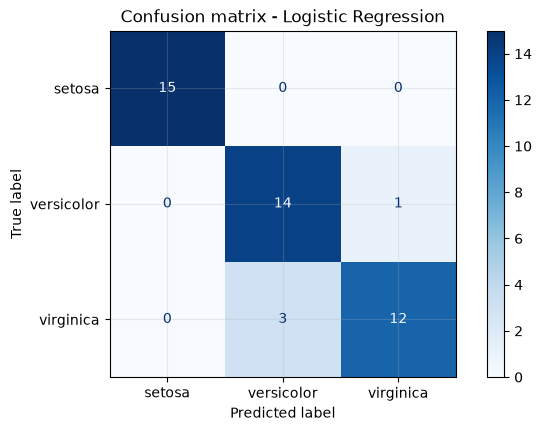

In [8]:
# Confusion matrix arată unde greșește modelul, nu doar cât greșește.
# La Iris, ne așteptăm ca setosa să fie simplă, iar confuziile să apară între versicolor și virginica.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
)
plt.title("Confusion matrix - Logistic Regression")
plt.show()


La Iris, cele mai multe greșeli apar între `versicolor` și `virginica`. `setosa` este aproape trivial de separat.


## 5. `predict_proba()` vs `predict()`

Pentru fiecare rând, `predict_proba()` întoarce 3 probabilități: una pentru fiecare clasă.

`predict()` alege clasa cu probabilitatea cea mai mare.

În multiclass, `predict()` este practic:

```python
np.argmax(predict_proba, axis=1)
```


In [9]:
# Construim un tabel de audit: probabilitățile modelului + predicția finală + adevărul.
# Asta face vizibilă diferența dintre scor/probabilitate și decizie.
proba_table = pd.DataFrame(y_proba, columns=[f"proba_{name}" for name in class_names], index=X_test.index)
proba_table["predict"] = [class_names[i] for i in y_pred]
proba_table["actual"] = [class_names[i] for i in y_test]

# În multiclass, probabilitățile de pe fiecare rând trebuie să însumeze 1.
display(proba_table.head(10).round(3))
print("Fiecare rând sumează la 1:", np.allclose(y_proba.sum(axis=1), 1))


,proba_setosa,proba_versicolor,proba_virginica,predict,actual
107,0.000,0.101,0.899,virginica,virginica
63,0.014,0.789,0.196,versicolor,versicolor
133,0.004,0.620,0.376,versicolor,virginica
56,0.022,0.629,0.349,versicolor,versicolor
127,0.005,0.385,0.610,virginica,virginica
140,0.000,0.022,0.978,virginica,virginica
53,0.016,0.915,0.070,versicolor,versicolor
69,0.034,0.939,0.028,versicolor,versicolor
20,0.938,0.062,0.000,setosa,setosa
141,0.000,0.055,0.945,virginica,virginica


Fiecare rând sumează la 1: True


In [10]:
# Reconstruim manual predict(): alegem coloana cu probabilitatea maximă.
# Nu reconstruim modelul, doar arătăm regula de decizie folosită după predict_proba().
manual_pred = np.argmax(y_proba, axis=1)
print("Identic cu model.predict():", np.array_equal(manual_pred, y_pred))

pd.DataFrame(
    {
        "proba_max": y_proba.max(axis=1).round(3),
        "predict()": [class_names[i] for i in y_pred],
        "manual_argmax": [class_names[i] for i in manual_pred],
        "adevăr": [class_names[i] for i in y_test],
    }
).head(10)


Identic cu model.predict(): True


,proba_max,predict(),manual_argmax,adevăr
0,0.899,virginica,virginica,virginica
1,0.789,versicolor,versicolor,versicolor
2,0.620,versicolor,versicolor,virginica
3,0.629,versicolor,versicolor,versicolor
4,0.610,virginica,virginica,virginica
5,0.978,virginica,virginica,virginica
6,0.915,versicolor,versicolor,versicolor
7,0.939,versicolor,versicolor,versicolor
8,0.938,setosa,setosa,setosa
9,0.945,virginica,virginica,virginica


Diferența practică:

- `predict_proba()` păstrează cât de sigur este modelul;
- `predict()` transformă probabilitățile într-o decizie finală.

Un exemplu cu probabilități `[0.02, 0.49, 0.49]` este mult mai fragil decât unul cu `[0.01, 0.02, 0.97]`, chiar dacă ambele au o clasă câștigătoare.


## 6. Praguri: transformăm multiclass într-o întrebare one-vs-rest

Pragurile se înțeleg cel mai bine în clasificare binară. Ca să păstrăm Iris, formulăm o întrebare practică:

> "Vrem să detectăm florile `virginica`."

Acum avem:

- pozitiv = `virginica`;
- negativ = orice altă specie.

Folosim probabilitatea modelului pentru clasa `virginica` și testăm praguri diferite.


In [11]:
# Pentru praguri avem nevoie de o întrebare binară.
# O transformăm în: "este floarea virginica sau nu?".
virginica_id = class_names.index("virginica")
y_test_virginica = (y_test == virginica_id).astype(int)
proba_virginica = y_proba[:, virginica_id]

# Funcție mică de evaluare: aceeași probabilitate, praguri diferite, decizii diferite.
def metrics_at_threshold(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "predicted_positive_rate": pred.mean(),
    }

# Testăm praguri dese, ca să vedem cum se mișcă balanța precision-recall.
thresholds = np.arange(0.05, 0.96, 0.05)
threshold_table = pd.DataFrame(
    [metrics_at_threshold(y_test_virginica, proba_virginica, t) for t in thresholds]
)

display(threshold_table.round(3))


,threshold,accuracy,precision,recall,f1,predicted_positive_rate
0,0.05,0.733,0.556,1.000,0.714,0.600
1,0.10,0.778,0.600,1.000,0.750,0.556
2,0.15,0.822,0.652,1.000,0.789,0.511
3,0.20,0.889,0.750,1.000,0.857,0.444
4,0.25,0.933,0.833,1.000,0.909,0.400
5,0.30,0.956,0.882,1.000,0.938,0.378
6,0.35,0.978,0.938,1.000,0.968,0.356
7,0.40,0.933,0.929,0.867,0.897,0.311
8,0.45,0.911,0.923,0.800,0.857,0.289
9,0.50,0.911,0.923,0.800,0.857,0.289


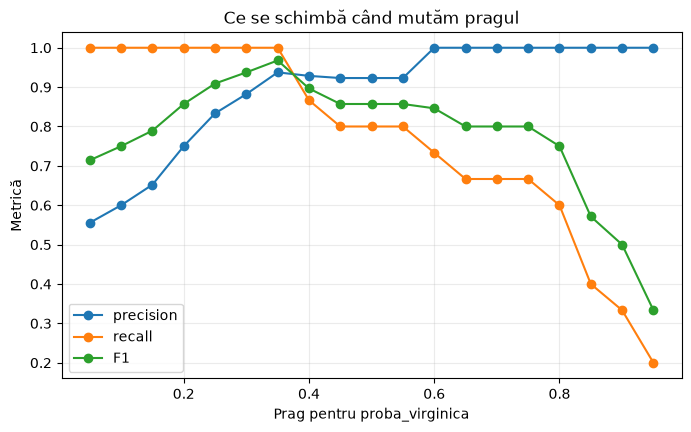

In [12]:
# Graficul face compromisurile mai clare decât tabelul: când crește precision, recall poate scădea.
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="recall")
plt.plot(threshold_table["threshold"], threshold_table["f1"], marker="o", label="F1")
plt.xlabel("Prag pentru proba_virginica")
plt.ylabel("Metrică")
plt.title("Ce se schimbă când mutăm pragul")
plt.legend()
plt.show()


In [13]:
# Varianta 1: alegem pragul care maximizează F1, adică un compromis simplu precision-recall.
best_f1_row = threshold_table.loc[threshold_table["f1"].idxmax()]

# Varianta 2: impunem o regulă de business.
# Aici vrem recall mare pentru virginica, dar alegem dintre pragurile eligibile pe cel cu precision maxim.
eligible = threshold_table[threshold_table["recall"] >= 0.90]
best_recall_constrained = eligible.loc[eligible["precision"].idxmax()]

print("Cel mai bun prag după F1:")
display(best_f1_row.to_frame().T.round(3))

print("Cel mai bun prag cu recall >= 0.90:")
display(best_recall_constrained.to_frame().T.round(3))


Cel mai bun prag după F1:


,threshold,accuracy,precision,recall,f1,predicted_positive_rate
6,0.35,0.978,0.938,1.0,0.968,0.356


Cel mai bun prag cu recall >= 0.90:


,threshold,accuracy,precision,recall,f1,predicted_positive_rate
6,0.35,0.978,0.938,1.0,0.968,0.356


Ce aș alege pentru cazul nostru:

- pentru clasificare generală Iris: `macro F1` sau `accuracy`, fiindcă clasele sunt echilibrate;
- pentru întrebarea "găsește `virginica`": aș alege pragul după F1 dacă precision și recall contează similar;
- dacă ratarea unei `virginica` costă mai mult, aș impune recall minim și aș alege cel mai precis prag care respectă constrângerea.


## 7. Nivelul de cod: ce scriem noi și ce nu?

Nu scriem de la zero:

- sigmoid / softmax;
- funcția de loss;
- optimizarea coeficienților;
- regularizarea;
- calculul probabilităților.

Scriem noi:

- pipeline-ul;
- split-ul corect;
- comparația cu baseline;
- alegerea metricii;
- alegerea pragului;
- testele de underfit/overfit;
- explicația pentru oameni.

În practică, un notebook bun nu arată că știi să reinventezi `sklearn`. Arată că știi să pui întrebarea corectă și să verifici modelul corect.


## 8. Underfit: model prea slab

Forțăm underfit folosind doar o variabilă și regularizare foarte puternică.

`C` este inversul regularizării:

- `C` mic = model foarte constrâns;
- `C` mare = model mai liber.


In [14]:
# Underfit intenționat: îi dăm modelului un singur feature și îl constrângem puternic cu C foarte mic.
# Ne așteptăm ca scorurile să fie slabe atât pe train, cât și pe test.
underfit = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=0.001, max_iter=2000, random_state=RANDOM_STATE)),
    ]
)

# Folosim doar sepal width, un feature mult mai slab decât măsurătorile petalelor.
X_train_under = X_train[["sepal width (cm)"]]
X_test_under = X_test[["sepal width (cm)"]]

underfit.fit(X_train_under, y_train)
underfit_pred = underfit.predict(X_test_under)
underfit_proba = underfit.predict_proba(X_test_under)

print(classification_report(y_test, underfit_pred, target_names=class_names, zero_division=0))
print("Accuracy:", round(accuracy_score(y_test, underfit_pred), 3))
print("Macro F1:", round(f1_score(y_test, underfit_pred, average="macro"), 3))
print("Log loss:", round(log_loss(y_test, underfit_proba), 3))


              precision    recall  f1-score   support

      setosa       0.70      0.93      0.80        15
  versicolor       0.48      0.80      0.60        15
   virginica       0.00      0.00      0.00        15

    accuracy                           0.58        45
   macro avg       0.39      0.58      0.47        45
weighted avg       0.39      0.58      0.47        45

Accuracy: 0.578
Macro F1: 0.467
Log loss: 1.087


Semne de underfit:

- train și test sunt ambele slabe;
- modelul nu are informație suficientă;
- regularizarea îl ține prea aproape de predicții banale;
- mutarea pragului nu rezolvă separarea slabă.


## 9. Overfit: model prea liber

Iris este mic. Putem forța overfit prin `PolynomialFeatures` cu grad mare și regularizare foarte slabă.

Modelul devine capabil să învețe forme inutile din train, dar asta nu înseamnă că generalizează mai bine.


In [15]:
# Overfit intenționat: adăugăm multe combinații polinomiale și slăbim regularizarea cu C foarte mare.
# Modelul are multă libertate; comparația train vs test ne spune dacă libertatea ajută sau doar memorează.
overfit = Pipeline(
    steps=[
        ("poly", PolynomialFeatures(degree=8, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=10000, max_iter=10000, random_state=RANDOM_STATE)),
    ]
)

overfit.fit(X_train, y_train)

# Salvăm separat scorurile pe train și test ca să vedem gap-ul de generalizare.
overfit_train_proba = overfit.predict_proba(X_train)
overfit_test_proba = overfit.predict_proba(X_test)
overfit_train_pred = overfit.predict(X_train)
overfit_test_pred = overfit.predict(X_test)

print("Train accuracy:", round(accuracy_score(y_train, overfit_train_pred), 3))
print("Test accuracy :", round(accuracy_score(y_test, overfit_test_pred), 3))
print("Train macro F1:", round(f1_score(y_train, overfit_train_pred, average="macro"), 3))
print("Test macro F1 :", round(f1_score(y_test, overfit_test_pred, average="macro"), 3))
print("Train log loss:", round(log_loss(y_train, overfit_train_proba), 3))
print("Test log loss :", round(log_loss(y_test, overfit_test_proba), 3))


Train accuracy: 1.0
Test accuracy : 0.889
Train macro F1: 1.0
Test macro F1 : 0.886
Train log loss: 0.0
Test log loss : 0.652


Semne de overfit:

- train este mult mai bun decât test;
- modelul este greu de explicat;
- adaugi complexitate, dar câștigul pe test nu este stabil;
- coeficienții nu mai sunt ușor de citit, pentru că ai multe combinații artificiale de features.


## 10. Găsim locul bun

Căutăm controlat:

- grad polinomial: 1, 2, 3;
- regularizare: mai multe valori de `C`;
- metrică de selecție: `f1_macro`, fiindcă vrem performanță echilibrată pe toate clasele.

Folosim cross-validation pe train. Testul rămâne pentru verificarea finală.


In [16]:
# Căutăm o zonă rezonabilă între model prea simplu și model prea flexibil.
# Pipeline-ul permite ca GridSearchCV să testeze corect fiecare combinație de preprocessing + model.
search_pipe = Pipeline(
    steps=[
        ("poly", PolynomialFeatures(include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
    ]
)

# degree controlează complexitatea feature-urilor; C controlează regularizarea.
param_grid = {
    "poly__degree": [1, 2, 3],
    "model__C": [0.01, 0.1, 1, 10, 100],
}

# StratifiedKFold păstrează distribuția claselor în fiecare fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Optimizăm macro F1 ca să tratăm cele 3 specii echilibrat.
grid = GridSearchCV(
    search_pipe,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

grid.fit(X_train, y_train)

# Afișăm topul combinațiilor; train vs validation ajută la detectarea overfit-ului.
results = pd.DataFrame(grid.cv_results_)
display(
    results[
        ["param_poly__degree", "param_model__C", "mean_train_score", "mean_test_score", "std_test_score"]
    ]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
    .round(3)
)

print("Best params:", grid.best_params_)
print("Best CV macro F1:", round(grid.best_score_, 3))


,param_poly__degree,param_model__C,mean_train_score,mean_test_score,std_test_score
11,3,10.0,1.000,0.990,0.019
12,1,100.0,1.000,0.990,0.019
4,2,0.1,0.979,0.981,0.023
5,3,0.1,0.981,0.981,0.023
6,1,1.0,0.979,0.981,0.023
7,2,1.0,0.986,0.981,0.023
8,3,1.0,0.990,0.981,0.023
9,1,10.0,0.988,0.981,0.023
10,2,10.0,0.998,0.981,0.023
13,2,100.0,1.000,0.981,0.023


Best params: {'model__C': 10, 'poly__degree': 3}
Best CV macro F1: 0.99


In [17]:
# Luăm modelul ales prin cross-validation și îl evaluăm o singură dată pe test.
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)

print(classification_report(y_test, best_pred, target_names=class_names))
print("Accuracy:", round(accuracy_score(y_test, best_pred), 3))
print("Macro F1:", round(f1_score(y_test, best_pred, average="macro"), 3))
print("Log loss:", round(log_loss(y_test, best_proba), 3))
print("AUC ROC OvR:", round(roc_auc_score(y_test, best_proba, multi_class="ovr"), 3))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45

Accuracy: 0.911
Macro F1: 0.91
Log loss: 0.17
AUC ROC OvR: 0.996


La Iris, este posibil ca modelul simplu să fie deja aproape perfect. Asta este o lecție bună: când datele sunt simple și features sunt bune, complexitatea nu adaugă mare lucru.


## 11. Comparație finală

Comparăm modelele în același tabel.


In [18]:
# O funcție mică ține comparația finală curată și reduce riscul de a calcula metrici diferit între modele.
def evaluate_multiclass(name, y_true, pred, proba):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro"),
        "weighted_f1": f1_score(y_true, pred, average="weighted"),
        "log_loss": log_loss(y_true, proba),
        "auc_ovr": roc_auc_score(y_true, proba, multi_class="ovr"),
    }

# Toate variantele ajung în același tabel, ca alegerea finală să fie justificată vizibil.
comparison = pd.DataFrame(
    [
        evaluate_multiclass("dummy", y_test, dummy_pred, dummy_proba),
        evaluate_multiclass("underfit", y_test, underfit_pred, underfit_proba),
        evaluate_multiclass("logistic standard", y_test, y_pred, y_proba),
        evaluate_multiclass("overfit poly 8", y_test, overfit_test_pred, overfit_test_proba),
        evaluate_multiclass("grid search", y_test, best_pred, best_proba),
    ]
)

display(comparison.sort_values("macro_f1", ascending=False).round(3))


,model,accuracy,macro_f1,weighted_f1,log_loss,auc_ovr
2,logistic standard,0.911,0.911,0.911,0.210,0.996
4,grid search,0.911,0.910,0.910,0.170,0.996
3,overfit poly 8,0.889,0.886,0.886,0.652,0.997
1,underfit,0.578,0.467,0.467,1.087,0.790
0,dummy,0.333,0.167,0.167,24.029,0.500


Alegerea mea pentru cazul nostru: `logistic standard`, dacă scorul este la fel de bun sau aproape la fel de bun ca grid search.

Motivul: este simplu, stabil, explicabil și suficient. Grid search este util ca verificare, dar nu trebuie să alegem un model mai complex doar pentru că există.


## 12. Interpretare: coeficienți

Coeficienții spun cum se modifică log-odds pentru fiecare clasă.

În multiclass avem câte un set de coeficienți pentru fiecare specie. Un coeficient mare pozitiv înseamnă că feature-ul împinge modelul spre clasa respectivă.


In [19]:
# Scoatem modelul logistic din pipeline ca să citim coeficienții învățați.
# Pentru multiclass, sklearn păstrează un rând de coeficienți pentru fiecare clasă.
standard_scaler = logistic.named_steps["scaler"]
standard_model = logistic.named_steps["model"]

coef_table = pd.DataFrame(
    standard_model.coef_,
    columns=X.columns,
    index=class_names,
)

display(coef_table.round(3))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,-1.077,0.955,-1.700,-1.603
versicolor,0.473,-0.447,-0.116,-0.793
virginica,0.604,-0.507,1.816,2.396


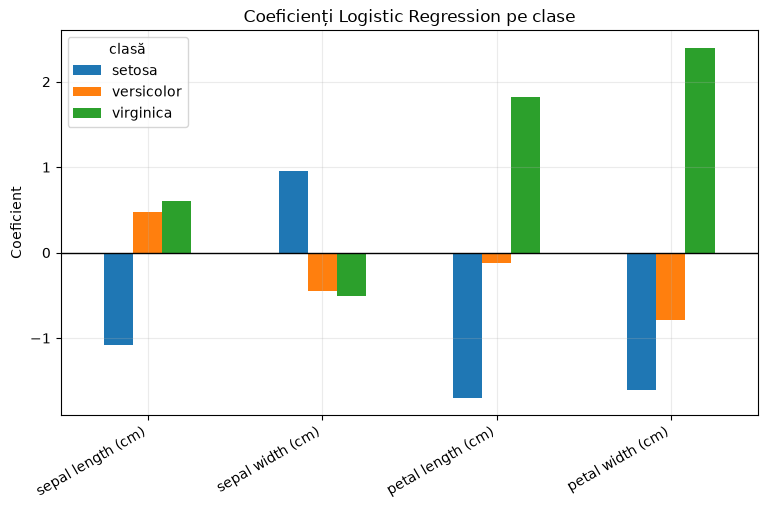

In [20]:
# Transpunem tabelul ca fiecare feature să apară pe axa X, iar clasele să fie comparate prin bare.
coef_table.T.plot(kind="bar", figsize=(9, 5))
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Coeficient")
plt.title("Coeficienți Logistic Regression pe clase")
plt.xticks(rotation=30, ha="right")
plt.legend(title="clasă")
plt.show()


Citire rapidă:

- `setosa` se separă puternic prin petale mici;
- `virginica` este împinsă de petale mai mari;
- `versicolor` stă între ele și de aceea are cele mai multe confuzii.

Pentru explicații mai serioase, coeficienții sunt doar începutul. Putem adăuga permutation importance, calibrare și analiză de erori.


In [21]:
# Permutation importance răspunde la întrebarea: cât pierdem dacă amestecăm valorile unui feature?
# Este o interpretare model-agnostic: funcționează și pentru modele care nu au coeficienți simpli.
importance = permutation_importance(
    logistic,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=RANDOM_STATE,
)

importance_table = pd.DataFrame(
    {
        "feature": X.columns,
        "importance_mean": importance.importances_mean,
        "importance_std": importance.importances_std,
    }
).sort_values("importance_mean", ascending=False)

display(importance_table.round(3))


,feature,importance_mean,importance_std
3,petal width (cm),0.192,0.034
2,petal length (cm),0.182,0.052
1,sepal width (cm),0.039,0.022
0,sepal length (cm),0.009,0.018


## 13. Mini audit de cod

Un notebook bun de logistic regression ar trebui să poată răspunde la aceste întrebări:

1. Avem baseline?
2. Split-ul este stratificat?
3. Transformările sunt într-un pipeline?
4. Comparăm `predict_proba()` cu `predict()`?
5. Alegem metrici potrivite problemei?
6. Pentru praguri, formulăm clar problema binară sau one-vs-rest?
7. Avem exemple de underfit și overfit?
8. Căutarea modelului se face prin cross-validation?
9. Modelul ales este justificat, nu doar raportat?
10. Explicația include limitele modelului?


## 14. Teme mai avansate

Dacă nu mai ajungem să le facem în sesiune, acestea sunt teme bune pentru acasă.

### Tema A - ROC și Precision-Recall pentru fiecare clasă

Folosește `label_binarize(y_test, classes=[0, 1, 2])` și trasează ROC/PR pentru fiecare specie one-vs-rest.

Întrebare: care clasă este cel mai ușor de separat și care este cea mai ambiguă?

### Tema B - Calibrarea probabilităților

Împarte predicțiile în bucket-uri de probabilitate și compară:

- probabilitatea medie prezisă;
- rata reală de apariție.

Bonus: folosește `CalibratedClassifierCV`.

### Tema C - `multinomial` vs `ovr`

Compară:

```python
LogisticRegression(multi_class="multinomial")
LogisticRegression(multi_class="ovr")
```

Întrebare: se schimbă probabilitățile sau doar predicțiile finale?

### Tema D - L1 și L2

Testează regularizarea:

- `penalty="l2"`
- `OneVsRestClassifier(LogisticRegression(penalty="l1", solver="liblinear"))`

Întrebare: L1 elimină vreun feature?

### Tema E - Learning curve

Antrenează modelul pe 20%, 40%, 60%, 80%, 100% din train și compară train score vs validation score.

Întrebare: problema pare limitată de date sau de model?

### Tema F - Error analysis

Afișează rândurile greșite, probabilitățile lor și diferența dintre primele două probabilități.

Întrebare: greșelile sunt "încrezătoare" sau sunt cazuri apropiate de frontieră?

### Tema G - Decision boundary 2D

Reantrenează modelul doar pe:

- `petal length (cm)`
- `petal width (cm)`

Desenează frontiera de decizie în plan.

Întrebare: unde se suprapun `versicolor` și `virginica`?

### Tema H - Dataset mai realist

Repetă același template pe `load_breast_cancer()` sau pe un dataset Kaggle cu target binar.

Întrebare: ce se schimbă când clasele nu mai sunt echilibrate și features nu mai sunt atât de curate?


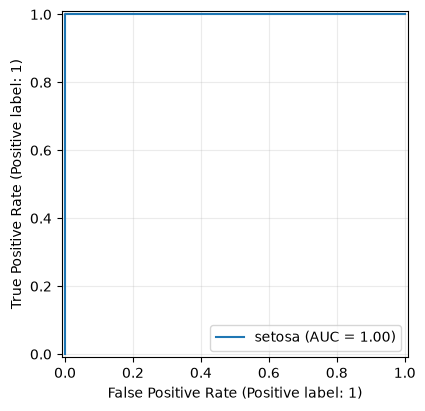

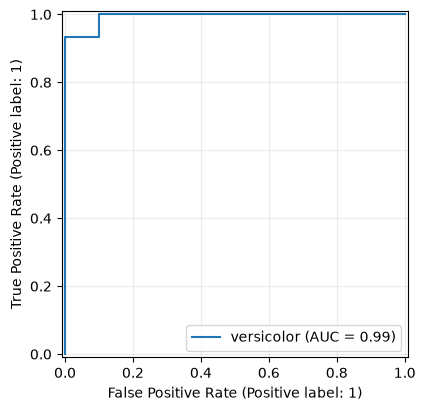

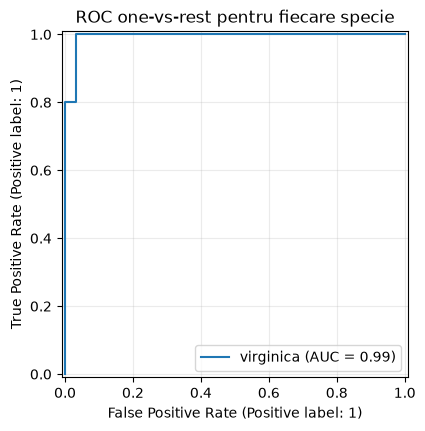

In [22]:
# Starter pentru Tema A: binarizare one-vs-rest.
# ROC este binar, deci transformăm fiecare clasă în "clasa asta" vs "restul".
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# Desenăm câte o curbă ROC pentru fiecare specie folosind probabilitatea clasei respective.
for class_id, class_name in enumerate(class_names):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, class_id],
        y_proba[:, class_id],
        name=class_name,
    )

plt.title("ROC one-vs-rest pentru fiecare specie")
plt.show()


In [23]:
# Starter pentru Tema F: exemple greșite.
# max_proba arată cât de sigur a fost modelul; margin_top2 arată cât de apropiate au fost primele două clase.
errors = X_test.copy()
errors["actual"] = [class_names[i] for i in y_test]
errors["predicted"] = [class_names[i] for i in y_pred]
errors["max_proba"] = y_proba.max(axis=1)
errors["margin_top2"] = np.sort(y_proba, axis=1)[:, -1] - np.sort(y_proba, axis=1)[:, -2]

# Sortăm după margin mic: acestea sunt cazurile cele mai ambigue pentru model.
display(
    errors[errors["actual"] != errors["predicted"]]
    .sort_values("margin_top2")
    .round(3)
)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),actual,predicted,max_proba,margin_top2
77,6.7,3.0,5.0,1.7,versicolor,virginica,0.561,0.124
134,6.1,2.6,5.6,1.4,virginica,versicolor,0.591,0.183
106,4.9,2.5,4.5,1.7,virginica,versicolor,0.608,0.240
133,6.3,2.8,5.1,1.5,virginica,versicolor,0.620,0.244


## Recapitulare

1. Pe Iris, logistic regression este un model foarte puternic pentru că features separă bine clasele.
2. `predict_proba()` dă probabilități pe clase; `predict()` alege clasa cu probabilitatea maximă.
3. Pragurile se discută natural în binar sau one-vs-rest, de exemplu "detectăm `virginica`".
4. Pentru multiclass echilibrat, `accuracy` și `macro F1` sunt metrici bune de pornire.
5. Underfit apare când modelul are prea puțină informație sau prea multă constrângere.
6. Overfit apare când modelul este prea complex pentru datele disponibile.
7. Modelul final se alege prin comparație, nu prin entuziasm.
8. Temele avansate duc notebook-ul spre nivel de proiect real: calibrare, regularizare, error analysis, learning curves și frontiere de decizie.
